# Separating bias from transport and stored solids

**Question:** How can we distinguish a gross feed bias from healthy transport and inventory changes before
interpreting a reconciliation residual?

Level 2 · Prerequisite: lesson 01 on flotation reconciliation. · Reading time: 40 minutes.

## Objectives

An optimizer can close the wrong equation perfectly. We will first create a healthy load transition with
no sensor noise, then move each channel back to the same material parcel. Next we will run the implemented
thickener model to expose a real inventory change in its synthetic finite-volume calculation. Only after
those two checks will we compare quadratic and Huber corrections on an injected feed bias. The purpose is
to learn an order of diagnosis: verify time support and storage assumptions, then assess the estimator.

## Setup

Work in a checkout of OreBridge with the notebook environment active. The computational methods live in
`data-pipeline/pipeline`, so the checkout is required; no released OreBridge PyPI distribution is implied.
Install the exact numerical dependencies once, outside this notebook:

```bash
pip install numpy==2.2.6 scipy==1.18.1 scikit-learn==1.9.1 matplotlib==3.11.2
```

Start the kernel with `OMP_NUM_THREADS=1`, `OPENBLAS_NUM_THREADS=1` and `MKL_NUM_THREADS=1`.
The setup finds the checkout from the working directory without printing a machine path.

In [1]:
# Use the pinned CPU environment and import the implemented scientific methods.
import json
import sys
import importlib.metadata
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "VERSION").is_file() and (p / "data-pipeline" / "pipeline").is_dir()
)
sys.path.insert(0, str(root / "data-pipeline"))
get_ipython().run_line_magic("matplotlib", "inline")
from pipeline.model.scenarios import generate, align, conservation_matrix, channel_specs
from pipeline.model.reconciliation import weighted_reconcile, robust_reconcile
from pipeline.model.thickener import simulate_thickener
specs = channel_specs()
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
for distribution in ["numpy", "scipy", "scikit-learn", "matplotlib"]:
    print(f"{distribution}: {importlib.metadata.version(distribution)}")

numpy: 2.2.6
scipy: 1.18.1
scikit-learn: 1.9.1
matplotlib: 3.11.2


## Data

Source owner: OreBridge, [repository](https://github.com/fsantibanezleal/CAOS_OreBridge), MIT; authored
synthetic class. `data-pipeline/pipeline/model/scenarios.py` defines all sixteen channels and the seeded
transport generator. `data-pipeline/pipeline/model/thickener.py` defines the finite-volume reference model.
The public replay `data/derived/PL-01/trace.json` documents the same channel contract. We generate seed 1000
locally and keep latent truth exclusively for this controlled validation, never as an inference input.

## Method

A balance compares quantities with the same material and temporal support. In this generator an upstream
load reaches channel $j$ after $d_j$ seconds. Let $D=14$ seconds be the largest declared delay. The package
forms $z_j(t)=y_j(t-(D-d_j))$: it uses only present or earlier observations, and the first $D$ rows remain
unavailable. This is an authored transport assumption, not an estimated residence-time distribution.
Conservation can be checked on the aligned parcel, but that check cannot verify that the assumed delays
match a real plant. The mineral-reconciliation reference motivates the balance; OreBridge's source code
specifies this particular delay operator ([reconciliation reference](https://doi.org/10.1016/j.mineng.2018.04.023)).

Set noise to zero first. If an instantaneous balance still fails, the discrepancy cannot be blamed on
random measurement error. All eleven factors are retained; their first nine rows concern dry solids and
the last two water. We normalize each factor by its own propagated standard uncertainty before comparing
them, rather than adding tonnes per hour to cubic metres per hour.

In [2]:
# Remove noise to isolate apparent imbalance caused by mismatched material times.
healthy = generate("healthy", seed=1000, noise=0)
matrix = conservation_matrix()
sigma = np.array([s["sigma"] for s in specs])
factor_sigma = np.sqrt((matrix * matrix) @ (sigma * sigma))
raw_residual = healthy.observed[14:] @ matrix.T
print(f"Largest simultaneous dry-solids residual: {np.max(np.abs(raw_residual[:, :9])):.6f} t/h")

Largest simultaneous dry-solids residual: 263.223537 t/h


Align the same observations with the implemented causal operator. Nothing is smoothed and no clean truth
is used to estimate a state. The comparison below asks whether transport alone explains the discrepancy
in this deliberately exact synthetic model. The normalized maximum across factors is convenient for
plotting, while the printed dry-solids residual retains a recognizable engineering unit.

Largest aligned dry-solids residual: 0.000000000000 t/h


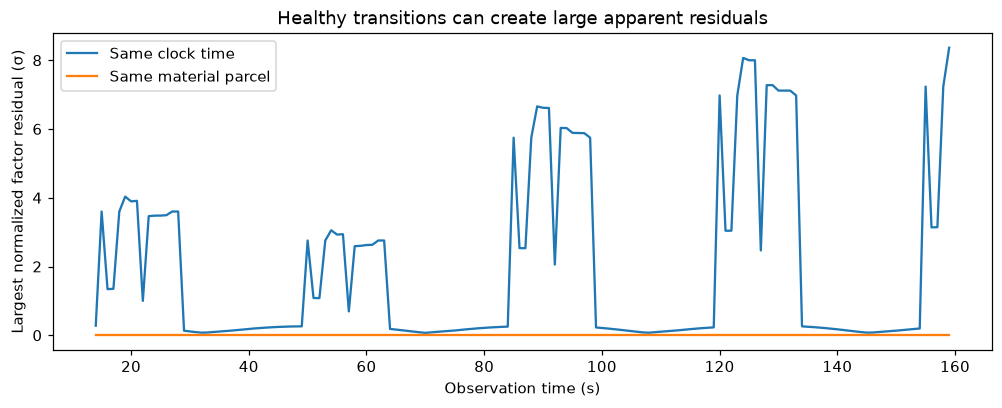

In [3]:
# Compare closure at clock time with closure at matched parcel time.
aligned_healthy = align(healthy.observed)
aligned_residual = aligned_healthy[14:] @ matrix.T
print(f"Largest aligned dry-solids residual: {np.max(np.abs(aligned_residual[:, :9])):.12f} t/h")
time_s = np.arange(14, len(healthy.observed))
raw_max = np.max(np.abs(raw_residual) / factor_sigma, axis=1)
aligned_max = np.max(np.abs(aligned_residual) / factor_sigma, axis=1)
fig, axis = plt.subplots(figsize=(9, 3.6), layout="constrained")
axis.plot(time_s, raw_max, label="Same clock time")
axis.plot(time_s, aligned_max, label="Same material parcel")
axis.set(title="Healthy transitions can create large apparent residuals", xlabel="Observation time (s)",
         ylabel="Largest normalized factor residual (σ)")
axis.legend()
plt.show()

The spikes belong to a healthy, noiseless process: upstream and downstream channels have sampled different
portions of a load change. Parcel alignment brings every factor to numerical zero because this experiment
was generated with exactly the same delays. That is a useful implementation check, not evidence that
fourteen seconds is a universal plant delay. With unknown mixing, recirculation or incorrect delay metadata,
one should estimate time support or decline to use that steady factor.

Transport is only one reason a junction equation can fail. A thickener stores solids, so its integrated
balance is $V_{s,\mathrm{in}}-V_{s,\mathrm{out}}=M_f-M_i$, where every term here is solids volume in m³.
The source model evolves a vertical solids fraction with a conservative finite-volume scheme and hindered
settling. We use 640 vertical cells. Its fixed geometry and two-hour run are teaching inputs; it excludes compression, flocculation
kinetics and radial flow. Run it rather than substituting a precomputed storage number.

In [4]:
# Run the finite-volume model and retain the integrated solids-volume accounting.
thickener = simulate_thickener(cells=640)
inventory_change = thickener["final_solids_m3"] - thickener["initial_solids_m3"]
volumes = np.array([thickener["feed_solids_m3"], thickener["outlet_solids_m3"]])
print(f"Change in stored solids: {inventory_change:.6f} m³")
print(f"Solids entering: {volumes[0]:.6f} m³; Solids leaving: {volumes[1]:.6f} m³")
print(f"Storage-aware closure residual: {thickener['solids_residual_m3']:.12f} m³")

Change in stored solids: -0.290800 m³
Solids entering: 3.200000 m³; Solids leaving: 3.490800 m³
Storage-aware closure residual: 0.000000000000 m³


Treat the two integrated volumes as a small reconciliation problem. We assign 0.05 m³ standard uncertainty
to each solely for this sensitivity exercise; the thickener code does not estimate sensor uncertainty.
First impose zero storage, then supply the independently computed inventory change as the right-hand side.
The same optimizer will succeed in both cases, so solver success cannot decide whether a physical equation
was appropriate. In an actual instrumented vessel, the inventory term requires its own measurement and uncertainty.

In [5]:
# Make the inventory assumption explicit in the equality's right-hand side.
volume_constraint = np.array([[1.0, -1.0]])
volume_sigma = np.array([0.05, 0.05])
naive_storage = weighted_reconcile(volumes, volume_sigma, volume_constraint, [0.0])
dynamic_storage = weighted_reconcile(volumes, volume_sigma, volume_constraint, [inventory_change])
naive_move = np.max(np.abs(naive_storage["state"] - volumes))
dynamic_move = np.max(np.abs(dynamic_storage["state"] - volumes))
print(f"Largest movement when storage is ignored: {naive_move:.6f} m³; "
      f"with storage included: {dynamic_move:.12f} m³")

Largest movement when storage is ignored: 0.145400 m³; with storage included: 0.000000000000 m³


Display the simulated inventory trajectory together with the two reconciled volume pairs. This connects
a time-dependent state to the integrated balance rather than interpreting a positive inflow-minus-outflow
difference as a loss. The totals cover the complete two-hour run even though the timeline is sampled more
sparsely for display; they come directly from the conservative model's accounting.

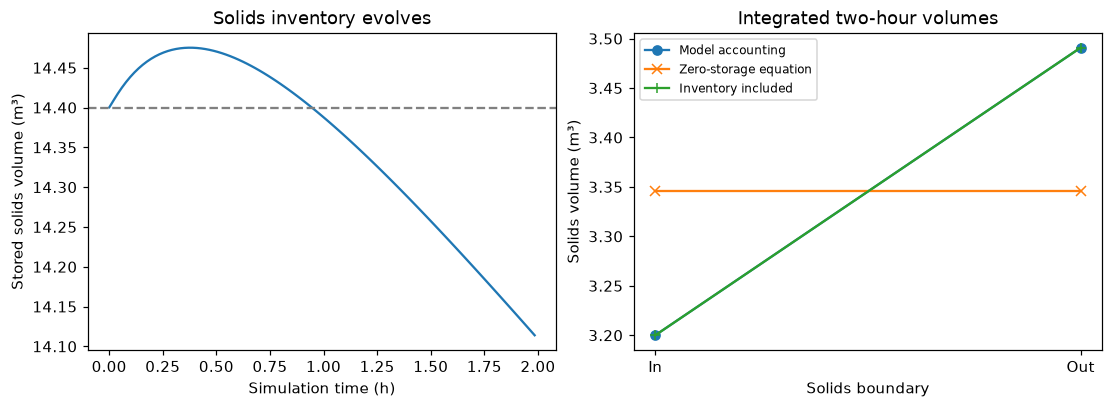

In [6]:
# Contrast real modeled accumulation with the artificial corrections of a steady assumption.
timeline = np.array(thickener["timeline"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
axes[0].plot(timeline[:, 0], timeline[:, 3])
axes[0].axhline(thickener["initial_solids_m3"], color="grey", linestyle="--")
axes[0].set(title="Solids inventory evolves", xlabel="Simulation time (h)",
            ylabel="Stored solids volume (m³)")
series = [(volumes, "o", "Model accounting"),
          (naive_storage["state"], "x", "Zero-storage equation"),
          (dynamic_storage["state"], "+", "Inventory included")]
for values, marker, name in series:
    axes[1].plot([0, 1], values, marker=marker, label=name)
axes[1].set_xticks([0, 1], ["In", "Out"])
axes[1].set(title="Integrated two-hour volumes", xlabel="Solids boundary", ylabel="Solids volume (m³)")
axes[1].legend(fontsize=8)
plt.show()

After an initial rise, the final solids inventory is below its starting value; integrated outlet volume exceeds feed.
The dynamic equation preserves those modeled totals. A zero-storage equation instead drags both totals
toward a common value and would manufacture two sensor corrections. The trajectory does not validate an
industrial thickener: its purpose is to expose the omitted inventory-change term. Time alignment cannot
remove a nonzero inventory term: the vessel first gains solids and finishes with less stored solids than it started with.

We can now investigate a genuine injected numerical bias with time support held fixed. The generator adds
sixteen standard uncertainties to the flotation feed during its fault interval at severity four. Huber
reconciliation minimizes $\sum_j\rho_{1.5}((x_j-y_j)/\sigma_j)$ under the same conservation equations, where
$\rho_\delta(r)=r^2/2$ for $|r|\leq\delta$ and $\delta(|r|-\delta/2)$ otherwise
([Huber, 1964](https://doi.org/10.1214/aoms/1177703732)). Its iterative weights shrink large-residual
influence; they do not prove the feed channel caused a discrepancy. The package performs the iterations.

In [7]:
# Compare estimators on the identical biased aligned row; reserve truth for evaluation.
biased = generate("bias", seed=1000, severity=4)
biased_row = align(biased.observed)[90]
validation_truth = align(biased.truth)[90]
quadratic = weighted_reconcile(biased_row, sigma, matrix, np.zeros(11))
robust = robust_reconcile(biased_row, sigma, matrix, np.zeros(11))
errors = np.column_stack([np.abs(quadratic["state"] - validation_truth) / sigma,
                          np.abs(robust["state"] - validation_truth) / sigma])
print(f"Mean absolute state error, WLS: {errors[:, 0].mean():.6f} σ")
print(f"Mean absolute state error, Huber: {errors[:, 1].mean():.6f} σ; iterations: {robust['iterations']}")
print(f"Huber objective: {robust['objective']:.6f}")

Mean absolute state error, WLS: 1.105407 σ
Mean absolute state error, Huber: 0.304784 σ; iterations: 20
Huber objective: 31.753924


Use the known synthetic truth to examine where each estimate moved. A mean error alone could conceal
leakage of the biased feed into neighboring flow estimates. Showing every channel makes that redistribution
visible. Sensor uncertainty is the normalization unit here; this is an error comparison, distinct from the
residual score used for alarms and distinct again from causal fault identification.

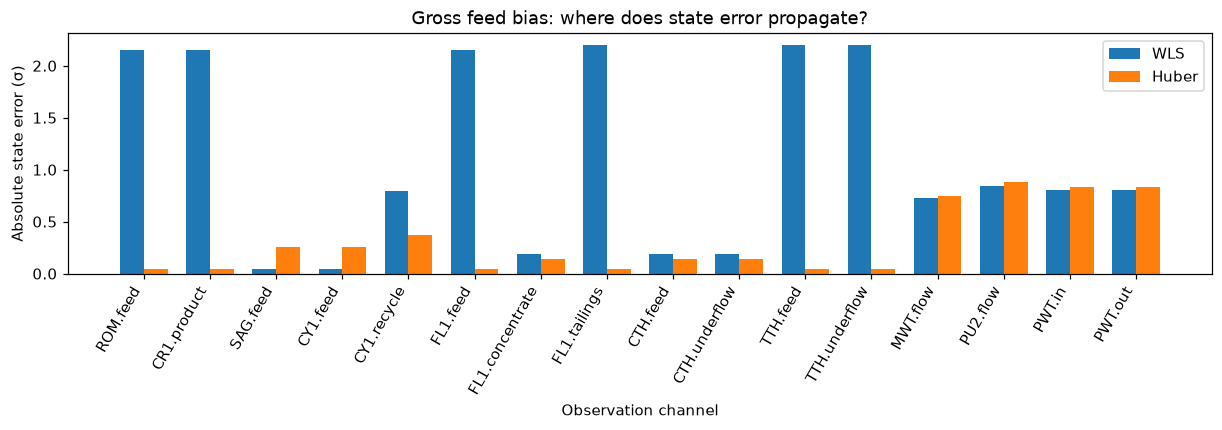

In [8]:
# Reveal the distribution of state error instead of reporting only a pooled mean.
positions = np.arange(16)
fig, axis = plt.subplots(figsize=(11, 3.8), layout="constrained")
axis.bar(positions - 0.18, errors[:, 0], 0.36, label="WLS")
axis.bar(positions + 0.18, errors[:, 1], 0.36, label="Huber")
axis.set_xticks(positions, [s["id"] for s in specs], rotation=60, ha="right")
axis.set(title="Gross feed bias: where does state error propagate?", xlabel="Observation channel",
         ylabel="Absolute state error (σ)")
axis.legend()
plt.show()

In this row, the Huber estimate contains the damage from the deliberately large feed bias better than the
quadratic projection. Some error remains, and the advantage is a property of this fault, uncertainty pattern
and chosen loss scale. It cannot be generalized to balanced process changes, missing observations or
misidentified topology. The next lesson tests exactly such a balanced change, where closing conservation
offers little help and learned temporal prediction asks a different question.

## Results

**Answer:** A healthy noiseless transition creates a 263.223537 t/h simultaneous dry-solids residual, which
falls to 0.000000000000 t/h at the displayed precision after parcel alignment. The thickener releases
0.290800 m³ of initial solids inventory; ignoring storage forces a needless 0.145400 m³ movement in each volume.
For the aligned biased row, mean normalized state error is 1.105407 σ with WLS and 0.304784 σ with Huber,
after 20 Huber iterations. Those are three different explanations, not three interchangeable alarm levels.

The correct sequence is physical before statistical: reject an unsupported instantaneous balance, include
inventory when it changes, and only then interpret how an estimator distributes an admitted discrepancy.
Quality metadata is another prerequisite; this experiment's finite accepted values do not test stale clocks,
incorrect units or broken tag bindings.

## Summary

A small residual can be manufactured by an incorrect equation, and a large residual can arise in a healthy
process. We used exact controlled cases to separate time support, stored material and a gross numerical
bias. Robustness helped only after the balance itself was justified. No fitted field delay, instrument
calibration or actual industrial thickener performance was inferred from these examples.

## References

- Sadeghi, Hodouin and Bazin (2018), mineral-processing reconciliation: https://doi.org/10.1016/j.mineng.2018.04.023
- Huber (1964), *Robust Estimation of a Location Parameter*: https://doi.org/10.1214/aoms/1177703732
- Executed definitions: `pipeline.model.scenarios.align`, `pipeline.model.thickener.simulate_thickener`,
  `pipeline.model.reconciliation.weighted_reconcile` and `robust_reconcile`.
- Assumptions and exclusions: `docs/architecture/01_plant-and-state.md` and the thickener module docstring.